## Testing different models 

## Model selection and evaluation strategy

We evaluate four models — Logistic Regression, Decision Tree, Random Forest, and XGBoost — for stroke detection. Because missing a true stroke (a false negative) can have severe consequences, our primary evaluation metric is **recall**: the proportion of actual stroke cases that the model correctly identifies. Maximizing recall helps ensure we capture as many true positive cases as possible, even if it increases false positives.

Why these models:
- **Logistic Regression** — Simple, fast, and highly interpretable; serves as a strong baseline and helps establish expected performance and feature directions.
- **Decision Tree** — Captures non-linear relationships and feature interactions while remaining interpretable; useful for quick insights and rule extraction.
- **Random Forest** — An ensemble of trees that reduces variance and improves robustness versus single trees; handles noisy features and mitigates overfitting.
- **XGBoost** — Gradient-boosted trees with strong predictive power on tabular data; offers fine-grained regularization and tuning options to balance recall and precision.

Practical approach:
- Use F1 and recall as the primary optimization objective (via class weights, threshold tuning, or custom scoring).
- Compare models on both resampled (e.g., SMOTE) and original data with class-weighted training to ensure generalization.
- Balance performance and interpretability depending on deployment needs (e.g., prefer simpler models for clinical explainability, ensembles for max recall).

In [121]:
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, matthews_corrcoef, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from xgboost import cv
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import VotingClassifier
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import shap
from sklearn.compose import ColumnTransformer


RANDOM_STATE = 42

In [159]:
# Load the cleaned data once and reuse the same stratified split for every experiment.


data = pd.read_csv("../data/cleaned.csv")
X = data.drop(columns=["stroke"])
y = data["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)


In [160]:
def train_and_evaluate_model(
    estimator_cls,
    estimator_params,
    X_train,
    X_test,
    y_train,
    y_test,
    *,
    model_name=None,
    use_smote=False, 
    threshold=None,
    cv_folds=None,
    cv_scoring="f1",
):
  
    preprocessor = ColumnTransformer(
        transformers=[('scaler', StandardScaler(), ['age', 'bmi', 'avg_glucose_level'])],
        remainder='passthrough'
    )
    
    steps = [("preprocessor", preprocessor)]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", estimator_cls(**estimator_params)))

    fitted_model = ImbPipeline(steps)

    cv_scores = None
    if cv_folds is not None and cv_folds > 1:
        cv = StratifiedKFold(
            n_splits=cv_folds,
            shuffle=True,
            random_state=RANDOM_STATE,
        )
        cv_scores = cross_val_score(
            clone(fitted_model),
            X_train,
            y_train,
            cv=cv,
            scoring=cv_scoring,
            n_jobs=-1,
        )

    fitted_model.fit(X_train, y_train)

    y_train_pred = fitted_model.predict(X_train)
    y_test_pred = fitted_model.predict(X_test)
    y_train_prob = None
    y_test_prob = None
    
    if hasattr(fitted_model, "predict_proba"):
        y_train_prob = fitted_model.predict_proba(X_train)[:, 1]
        y_test_prob = fitted_model.predict_proba(X_test)[:, 1]
        
        if threshold is not None:
            y_train_pred = (y_train_prob >= threshold).astype(int)
            y_test_pred = (y_test_prob >= threshold).astype(int)

    def _metrics(y_true, y_pred, y_prob=None):
        metrics = {
            "accuracy": accuracy_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "mcc": matthews_corrcoef(y_true, y_pred),
        }
        if y_prob is not None:
            metrics["roc_auc"] = roc_auc_score(y_true, y_prob)
            metrics["pr_auc"] = average_precision_score(y_true, y_prob)
        return metrics

    train_metrics = _metrics(y_train, y_train_pred, y_train_prob)
    test_metrics = _metrics(y_test, y_test_pred, y_test_prob)

    results = {
        "name": model_name or estimator_cls.__name__,
        "model": fitted_model,
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "y_train_pred": y_train_pred,
        "y_test_pred": y_test_pred,
        "y_train_prob": y_train_prob,
        "y_test_prob": y_test_prob,
        "train_confusion_matrix": confusion_matrix(y_train, y_train_pred),
        "test_confusion_matrix": confusion_matrix(y_test, y_test_pred),
        "train_report": classification_report(y_train, y_train_pred, zero_division=0),
        "test_report": classification_report(y_test, y_test_pred, zero_division=0),
        "train_metrics": train_metrics,
        "test_metrics": test_metrics,
        "cv_scores": cv_scores,
        "cv_mean": cv_scores.mean() if cv_scores is not None else None,
        "cv_std": cv_scores.std() if cv_scores is not None else None,
    }

    print(f"=== {results['name']} ===")
    if cv_scores is not None:
        print(f"CV {cv_scoring.upper()} Mean: {results['cv_mean']:.4f}")
        print(f"CV {cv_scoring.upper()} Std: {results['cv_std']:.4f}")
    print("Testing Data Metrics:")
    print("Confusion Matrix:")
    print(results["test_confusion_matrix"])
    print(results["test_report"])
    print(f"Accuracy Score: {test_metrics['accuracy']:.4f}")
    print(f"F1 Score: {test_metrics['f1']:.4f}")
    print(f"Precision Score: {test_metrics['precision']:.4f}")
    print(f"Recall Score: {test_metrics['recall']:.4f}")
    print(f"MCC: {test_metrics['mcc']:.4f}")
    if "roc_auc" in test_metrics:
        print(f"ROC-AUC Score: {test_metrics['roc_auc']:.4f}")
        print(f"PR-AUC Score: {test_metrics['pr_auc']:.4f}")
    if y_test_prob is not None and threshold is not None:
        print(f"Custom Threshold: {threshold}")

    return results


## best model parameters after applying grid search 

In [161]:
models = {
    "Logistic Regression": (
        LogisticRegression,
        {
            "max_iter": 2000,
            "class_weight": "balanced",
            "random_state": RANDOM_STATE,
        },
        False,  
        5,  
    ),

    "Decision Tree": (
        DecisionTreeClassifier,
        {
            "max_depth": 5,
            "min_samples_split": 20,
            "min_samples_leaf": 10,
            "class_weight": "balanced",
            "random_state": RANDOM_STATE,
        },
        False,  
        5,      
    ),

    "Random Forest": (
        RandomForestClassifier,
        {
            "n_estimators": 300,
            "max_depth": 8,
            "min_samples_leaf": 5,
            "class_weight": "balanced",
            "random_state": RANDOM_STATE,
            "n_jobs": -1,
        },
        False,  
        5,      
    ),

    "XGBoost Tuned": (
        XGBClassifier,
        {
            "n_estimators": 100,
            "max_depth": 3,
            "learning_rate": 0.1,
            "scale_pos_weight": 10,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
            "random_state": RANDOM_STATE,
            "eval_metric": "logloss",
        },
        False,  
        5,      
    ),
}


In [163]:
comparison_results = []
model_results = {} 
for model_name, (model_cls, params, use_smote, cv_folds) in models.items(): 
    result = train_and_evaluate_model( model_cls, params, X_train, X_test, y_train, y_test, model_name=model_name, use_smote=use_smote, cv_folds=cv_folds) 
    model_results[model_name] = result 
    comparison_results.append( { "Model": model_name, **result["test_metrics"], "cv_mean": result["cv_mean"], "cv_std": result["cv_std"], } )
comparison_df = pd.DataFrame(comparison_results).sort_values("f1", ascending=False) 
comparison_df

=== Logistic Regression ===
CV F1 Mean: 0.2280
CV F1 Std: 0.0216
Testing Data Metrics:
Confusion Matrix:
[[559 243]
 [  7  42]]
              precision    recall  f1-score   support

           0       0.99      0.70      0.82       802
           1       0.15      0.86      0.25        49

    accuracy                           0.71       851
   macro avg       0.57      0.78      0.53       851
weighted avg       0.94      0.71      0.78       851

Accuracy Score: 0.7062
F1 Score: 0.2515
Precision Score: 0.1474
Recall Score: 0.8571
MCC: 0.2735
ROC-AUC Score: 0.8495
PR-AUC Score: 0.2368
=== Decision Tree ===
CV F1 Mean: 0.2282
CV F1 Std: 0.0204
Testing Data Metrics:
Confusion Matrix:
[[567 235]
 [ 12  37]]
              precision    recall  f1-score   support

           0       0.98      0.71      0.82       802
           1       0.14      0.76      0.23        49

    accuracy                           0.71       851
   macro avg       0.56      0.73      0.53       851
weighted av

,Model,accuracy,f1,precision,recall,mcc,roc_auc,pr_auc,cv_mean,cv_std
3,XGBoost Tuned,0.816686,0.284404,0.183432,0.632653,0.268941,0.834775,0.211155,0.272139,0.024470
2,Random Forest,0.775558,0.268199,0.165094,0.714286,0.265847,0.841290,0.207484,0.259764,0.014248
0,Logistic Regression,0.706228,0.251497,0.147368,0.857143,0.273516,0.849483,0.236848,0.228037,0.021580
1,Decision Tree,0.709753,0.230530,0.136029,0.755102,0.230825,0.785027,0.190993,0.228169,0.020353


## creating a voting classifer

combined Logistic Regression and XGBoost using soft voting to leverage the complementary strengths of linear and tree-based learners.

In [164]:
voting_params = {
    'estimators': [
        ('xgb', XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, scale_pos_weight=10, random_state=RANDOM_STATE, eval_metric="logloss")),
        ('lr', LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ],
    'voting': 'soft'
}

voting_res = train_and_evaluate_model(
    estimator_cls=VotingClassifier,
    estimator_params=voting_params,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    model_name="Voting (XGB + LR)",
    use_smote=False,
    cv_folds=5
)

model_results["Voting (XGB + LR)"] = voting_res
comparison_results.append({
    "Model": "Voting (XGB + LR)",
    **voting_res["test_metrics"],
    "cv_mean": voting_res["cv_mean"],
    "cv_std": voting_res["cv_std"],
})
comparison_df = pd.DataFrame(comparison_results).sort_values("f1", ascending=False)
comparison_df

=== Voting (XGB + LR) ===
CV F1 Mean: 0.2725
CV F1 Std: 0.0122
Testing Data Metrics:
Confusion Matrix:
[[624 178]
 [  9  40]]
              precision    recall  f1-score   support

           0       0.99      0.78      0.87       802
           1       0.18      0.82      0.30        49

    accuracy                           0.78       851
   macro avg       0.58      0.80      0.58       851
weighted avg       0.94      0.78      0.84       851

Accuracy Score: 0.7803
F1 Score: 0.2996
Precision Score: 0.1835
Recall Score: 0.8163
MCC: 0.3172
ROC-AUC Score: 0.8468
PR-AUC Score: 0.2567


,Model,accuracy,f1,precision,recall,mcc,roc_auc,pr_auc,cv_mean,cv_std
4,Voting (XGB + LR),0.780259,0.299625,0.183486,0.816327,0.317191,0.846786,0.256737,0.272533,0.012186
3,XGBoost Tuned,0.816686,0.284404,0.183432,0.632653,0.268941,0.834775,0.211155,0.272139,0.024470
2,Random Forest,0.775558,0.268199,0.165094,0.714286,0.265847,0.841290,0.207484,0.259764,0.014248
0,Logistic Regression,0.706228,0.251497,0.147368,0.857143,0.273516,0.849483,0.236848,0.228037,0.021580
1,Decision Tree,0.709753,0.230530,0.136029,0.755102,0.230825,0.785027,0.190993,0.228169,0.020353


best model is the voting classifer (xgb+lr)

## feature importance 

/var/folders/01/_nbl43b94c714j63ptzqdmjc0000gn/T/ipykernel_28118/241069700.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


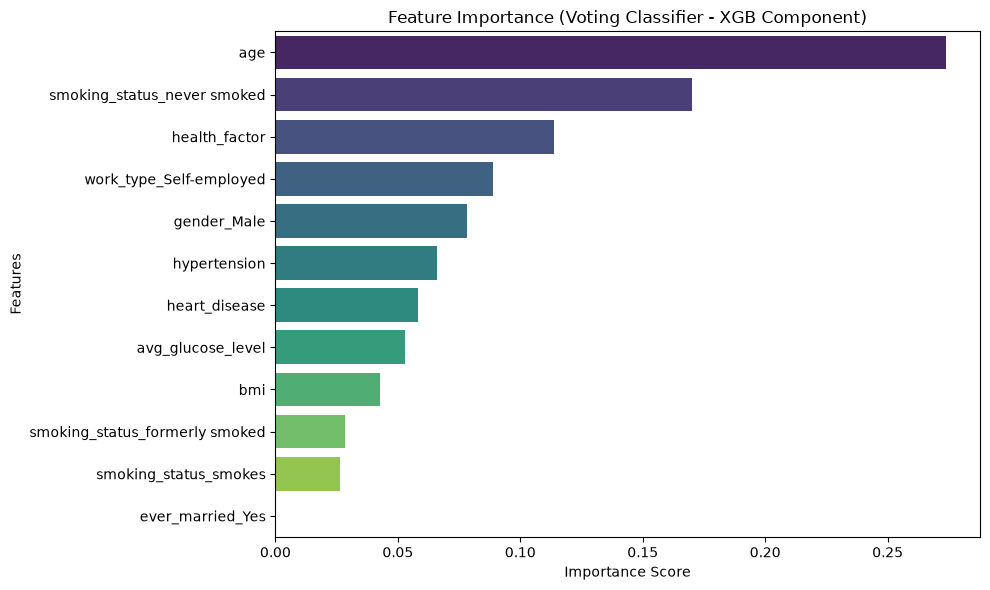

In [168]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. استخراج الـ Pipeline الرئيسي الكبير الخاص بنموذج الـ Voting
main_pipeline = model_results["Voting (XGB + LR)"]["model"]

# 2. استخراج موديل الـ Voting الفعلي من داخل الـ Pipeline الرئيسي
voting_model_actual = main_pipeline.named_steps['model']

# 3. [تم التصحيح] استخراج خوارزمية الـ XGBClassifier مباشرة (هو العنصر الأول في القائمة)
xgb_model_actual = voting_model_actual.estimators_[0]

# 4. قراءة الأوزان وأسماء الأعمدة بأمان تام
feature_importances = xgb_model_actual.feature_importances_
feature_names = X_train.columns

# 5. ربط البيانات وترتيبها تنازلياً ورسمها
importances_series = pd.Series(feature_importances, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=importances_series.values, 
    y=importances_series.index, 
    palette="viridis" 
)

plt.title("Feature Importance (Voting Classifier - XGB Component)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout() 
plt.show()


## SHAP Analysis 

Model interpretability was analyzed using SHAP on the XGBoost component of the ensemble because it captures the nonlinear relationships learned by the voting classifier.
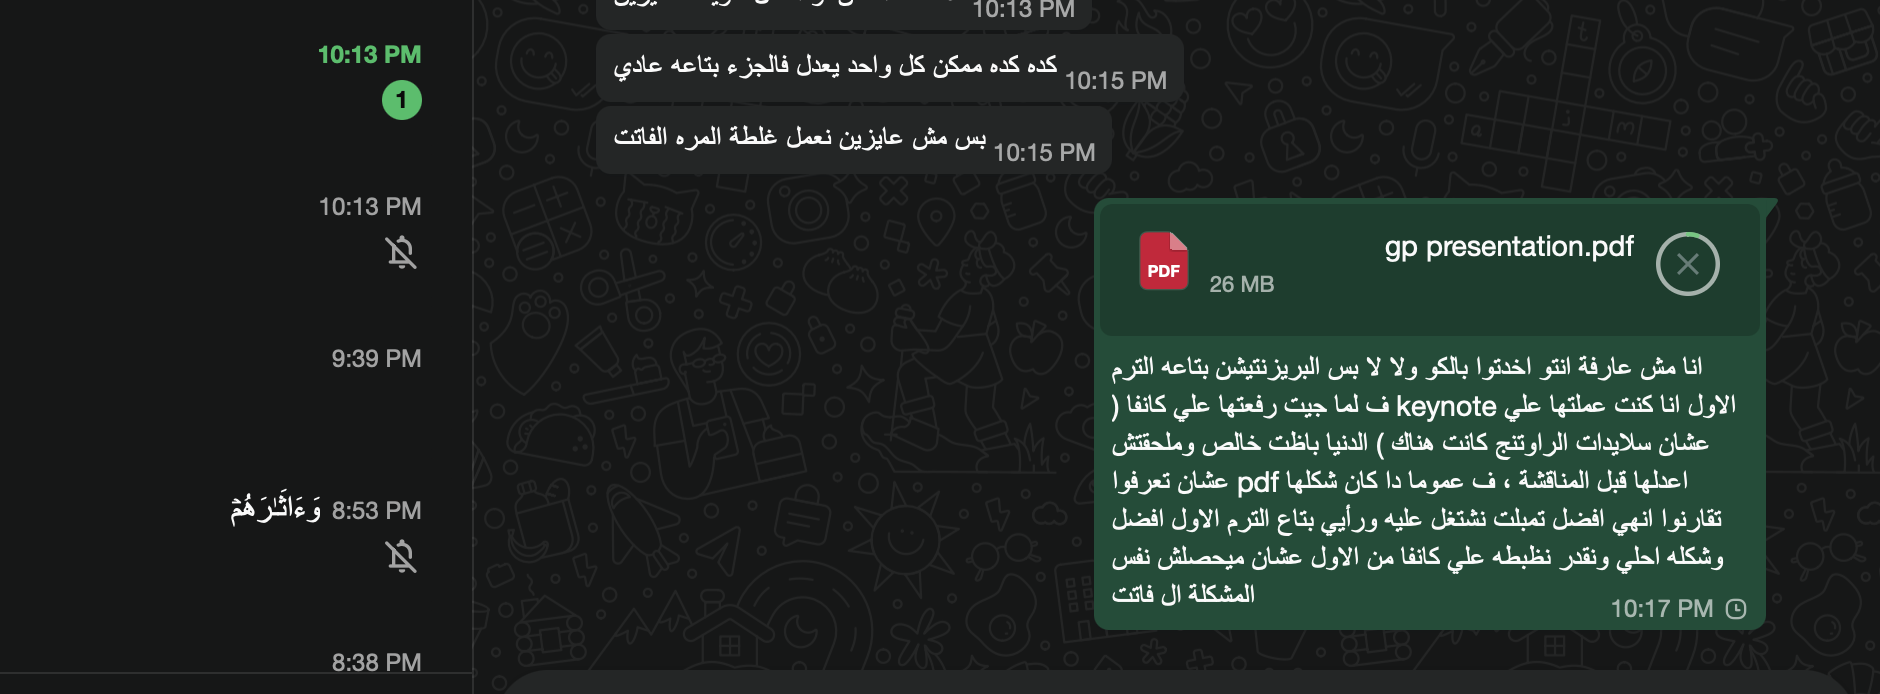

Background dataset has 3403 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=3403 when initializing the masker.
PermutationExplainer explainer: 852it [00:46, 15.08it/s]                         


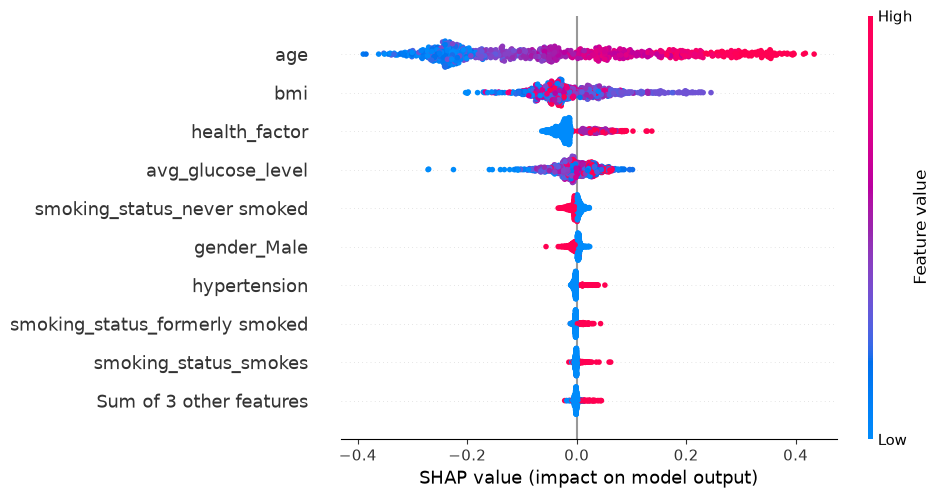

In [186]:
import shap
import pandas as pd

xgb_pipeline = model_results["XGBoost Tuned"]["model"]

prediction_function = lambda x: xgb_pipeline.predict_proba(pd.DataFrame(x, columns=X_test.columns))[:, 1]

explainer = shap.Explainer(prediction_function, X_train)
shap_values = explainer(X_test)

shap.plots.beeswarm(shap_values)


/var/folders/01/_nbl43b94c714j63ptzqdmjc0000gn/T/ipykernel_28118/1162264090.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


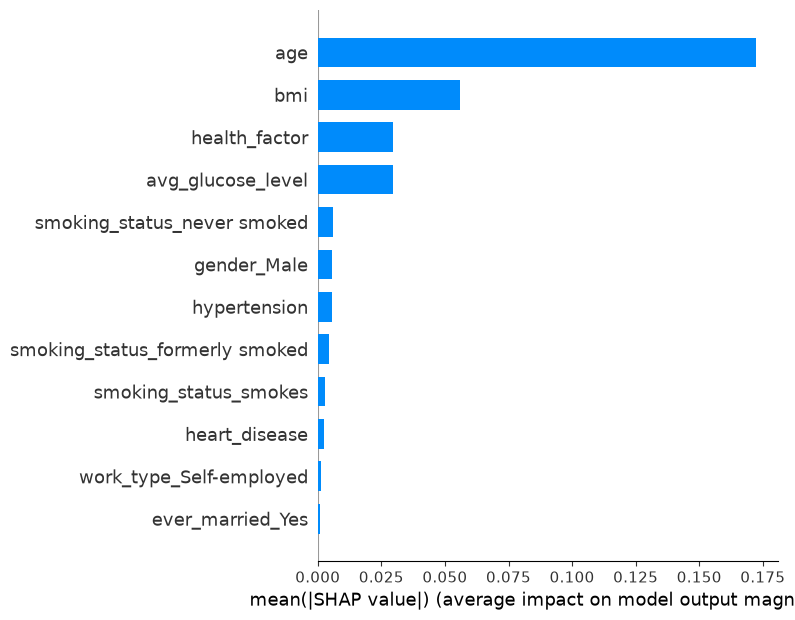

In [185]:
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)

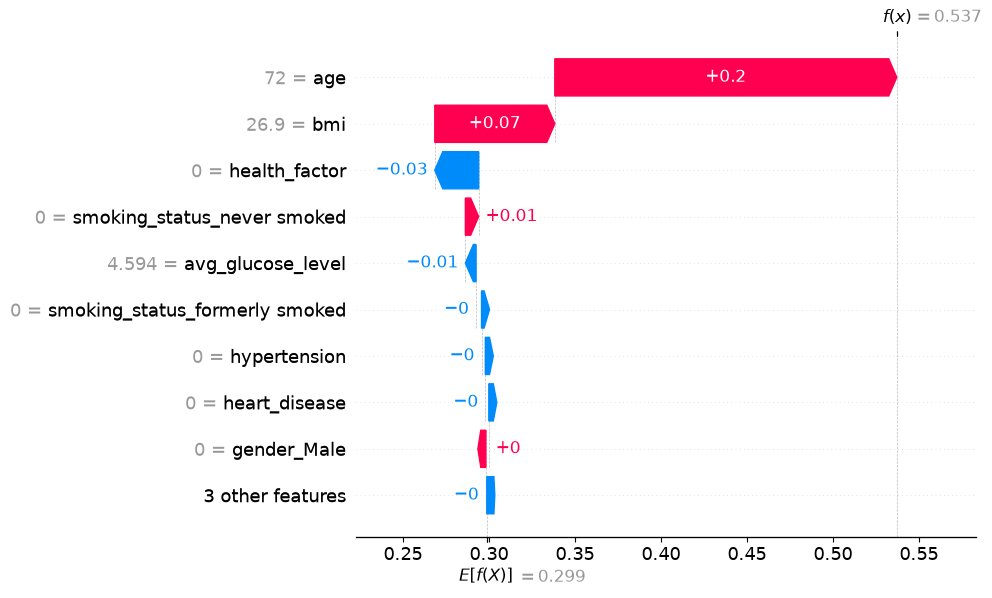

In [184]:
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[100].values, 
        base_values=shap_values[100].base_values, 
        data=X_test.iloc[100].values, 
        feature_names=X_test.columns 
    )
)
